<a href="https://colab.research.google.com/github/kirill-serebriakov/hw/blob/review/hw_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Серебряков Кирилл Олегович. РИ-431001.

# 1. Постановка задачи, которую хочется решать в рамках курса.

**1) Бизнес-постановка задачи:**
Разработка системы для автоматического поиска подозрительных сетевых потоков с помощью машинного обучения.

Цель: разработать прототип системы, которая с помощью машинного обучения будет анализировать сетевые потоки, находить подозрительное поведение и помогать специалистам по информационной безопасности быстрее выявлять возможные угрозы.

Важно, чтобы система не слишком часто ошибалась и не помечала обычных пользователей как подозрительных. Cистема будет только выдавать рекомендации: отмечать потоки, которые выглядят подозрительно, чтобы специалист мог проверить их дополнительно.

**2) Постановка ML-задачи:**

Задача: бинарная классификация сетевых потоков.

Для каждого наблюдения модель должна предсказать один из двух классов:

- 0 - нормальная активность: наблюдение не имеет подтверждённых признаков вредоносной активности.

- 1 - подозрительная активность: наблюдение связано с известной вредоносной активностью либо соответствует определённым критериям подозрительного поведения.

Для обучения модели предполагается использовать следующие признаки:

- source_port - порт отправителя;

- destination_port - порт получателя;

- protocol - протокол сетевого взаимодействия;

- flow_duration - длительность сетевого потока;

- total_fwd_packets - количество пакетов в прямом направлении;

- total_bwd_packets - количество пакетов в обратном направлении;

- flow_bytes_s - скорость передачи байтов;

- flow_packets_s - скорость передачи пакетов.

Модель возвращает прогнозируемый класс и оценку вероятности принадлежности к подозрительному классу.

**3) Набор данных для решения задачи:**
Для решения задачи выбран датасет [CIC-IDS2017](https://www.unb.ca/cic/datasets/ids-2017.html).

Датасет содержит сетевые характеристики, полученные в контролируемом эксперименте, а также метки нормального трафика и различных типов атак.
В этом датасете интересует вариант: GeneratedLabelledFlows. Он дополнительно содержит IP-адреса источника и назначения, что поможет анализировать активность отдельных адресов. Для определения страны и актуальной репутации IP-адресов потребуется дополнительно использовать внешние источники данных (по типу geoip).

# 2. Выбор и обоснование метрики для измерения качества.
В качестве основной метрики есть смысл использовать Recall, поскольку в задаче важно выявлять как можно больше подозрительных событий и минимизировать количество пропущенных атак. Дополнительно будем оценивать Precision, чтобы контролировать количество ложных срабатываний, и F1-score, который учитывает баланс между Precision и Recall.

# 3. EDA

**Подключение библиотек.**

In [ ]:
import os
import re
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

**Поиск файлов.**

In [ ]:
from google.colab import drive

DATA_DIR = "/content/CIC-IDS2017"

files = sorted(
    glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
)

print(f"Найдено CSV-файлов: {len(files)}")

for file in files:
    print(os.path.basename(file))

Найдено CSV-файлов: 8
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


**Загрузка необходимых столбцов.**

In [ ]:
# Поиск названий столбцов из разных CSV.
ALIASES = {
    "source_ip": {"sourceip", "srcip"},
    "destination_ip": {"destinationip", "dstip"},
    "source_port": {"sourceport", "srcport"},
    "destination_port": {"destinationport", "dstport"},
    "protocol": {"protocol"},
    "timestamp": {"timestamp"},
    "flow_duration": {"flowduration"},
    "total_fwd_packets": {
        "totalfwdpackets", "totalfwdpacket",
        "totalforwardpackets"
    },
    "total_bwd_packets": {
        "totalbackwardpackets", "totalbackwardpacket",
        "totalbwdpackets", "totalbwdpacket"
    },
    "flow_bytes_s": {"flowbytess", "flowbytespersecond"},
    "flow_packets_s": {"flowpacketss", "flowpacketspersecond"},
    "label": {"label"}
}

def normalize_column(name):
    """Убираем пробелы и знаки препинания из названия столбца."""
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

data_parts = []

for file in files:
    # Сначала читаем только заголовок, без самих данных.
    headers = pd.read_csv(file, nrows=0, encoding="cp1252").columns

    # Оставляем только интересующие нас столбцы.
    selected = [
        col for col in headers
        if any(
            normalize_column(col) in variants
            for variants in ALIASES.values()
        )
    ]

    if not selected:
        print(f"Пропущен файл без подходящих столбцов: {file}")
        continue

    part = pd.read_csv(
        file,
        usecols=selected,
        encoding="cp1252",
        low_memory=False
    )

    # Приводим названия столбцов к единообразному формату.
    rename = {}

    for col in part.columns:
        normalized = normalize_column(col)

        for standard_name, variants in ALIASES.items():
            if normalized in variants:
                rename[col] = standard_name
                break

    part = part.rename(columns=rename)
    data_parts.append(part)

if not data_parts:
    raise ValueError(
        "Некорректный путь и структуру CSV-файлов."
    )

df = pd.concat(data_parts, ignore_index=True)

# Удаляем строки без целевой метки и очищаем текстовые поля.
df["label"] = df["label"].astype("string").str.strip()

df = df.dropna(subset=["label"])
df = df[df["label"] != ""]

# Создаём вспомогательную метку для анализа:
# 0 - BENIGN, 1 - любой другой тип атаки.
df["is_suspicious"] = (
    df["label"].str.upper() != "BENIGN"
).astype(int)

# Приводим числовые признаки к числовому типу.
numeric_columns = [
    "source_port",
    "destination_port",
    "protocol",
    "flow_duration",
    "total_fwd_packets",
    "total_bwd_packets",
    "flow_bytes_s",
    "flow_packets_s"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df[numeric_columns] = df[
    [col for col in numeric_columns if col in df.columns]
].replace([np.inf, -np.inf], np.nan)

print("Размер таблицы:", df.shape)
display(df.head())

Размер таблицы: (2830743, 13)


,source_ip,source_port,destination_ip,destination_port,protocol,timestamp,flow_duration,total_fwd_packets,total_bwd_packets,flow_bytes_s,flow_packets_s,label,is_suspicious
0,104.16.207.165,443.0,192.168.10.5,54865.0,6.0,7/7/2017 3:30,3.0,2.0,0.0,4.000000e+06,666666.66670,BENIGN,0
1,104.16.28.216,80.0,192.168.10.5,55054.0,6.0,7/7/2017 3:30,109.0,1.0,1.0,1.100917e+05,18348.62385,BENIGN,0
2,104.16.28.216,80.0,192.168.10.5,55055.0,6.0,7/7/2017 3:30,52.0,1.0,1.0,2.307692e+05,38461.53846,BENIGN,0
3,104.17.241.25,443.0,192.168.10.16,46236.0,6.0,7/7/2017 3:30,34.0,1.0,1.0,3.529412e+05,58823.52941,BENIGN,0
4,104.19.196.102,443.0,192.168.10.5,54863.0,6.0,7/7/2017 3:30,3.0,2.0,0.0,4.000000e+06,666666.66670,BENIGN,0


Результат первичного осмотра данных:
1. Датасет содержит 2 830 743 строки и 13 столбцов.
2. Данные включают IP-адреса источника и назначения, порты, протокол, время, длительность сетевого потока, количество пакетов, скорость передачи данных и метки активности.
3. Столбец label содержит исходные метки трафика, например BENIGN, а is_suspicious - производный бинарный признак, где 0 означает нормальный трафик, а 1 - трафик с меткой атаки.
4. В таблице присутствуют как категориальные признаки (IP-адреса, метки), так и числовые (длительность, количество пакетов, скорость передачи данных).
5. В первых строках уже видны большие значения flow_bytes_s и flow_packets_s. В дальнейшем стоит проверить распределения этих признаков, а также наличие бесконечных значений и выбросов.

**Cтруктура набора данных.**

In [ ]:
print("\nТипы данных:")
df.info()

print("\nОписательная статистика числовых признаков:")
display(
    df.select_dtypes(include=np.number)
      .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
      .T.round(2)
)

print("\nКоличество уникальных IP:")
if "source_ip" in df.columns:
    print("IP-адресов источника:", df["source_ip"].nunique())

if "destination_ip" in df.columns:
    print("IP-адресов назначения:", df["destination_ip"].nunique())


Типы данных:
<class 'pandas.core.frame.DataFrame'>
Index: 2830743 entries, 0 to 3119344
Data columns (total 13 columns):
 #   Column             Dtype  
---  ------             -----  
 0   source_ip          object 
 1   source_port        float64
 2   destination_ip     object 
 3   destination_port   float64
 4   protocol           float64
 5   timestamp          object 
 6   flow_duration      float64
 7   total_fwd_packets  float64
 8   total_bwd_packets  float64
 9   flow_bytes_s       float64
 10  flow_packets_s     float64
 11  label              string 
 12  is_suspicious      int64  
dtypes: float64(8), int64(1), object(3), string(1)
memory usage: 302.4+ MB

Описательная статистика числовых признаков:


,count,mean,std,min,25%,50%,75%,95%,99%,max
source_port,2830743.0,41128.86,22294.94,0.0,32774.00,50944.00,58413.00,6.256600e+04,6.490800e+04,6.553500e+04
destination_port,2830743.0,8071.48,18283.63,0.0,53.00,80.00,443.00,5.522800e+04,6.165200e+04,6.553500e+04
protocol,2830743.0,9.88,5.26,0.0,6.00,6.00,17.00,1.700000e+01,1.700000e+01,1.700000e+01
flow_duration,2830743.0,14785663.93,33653744.09,-13.0,155.00,31316.00,3204828.50,1.011146e+08,1.177776e+08,1.200000e+08
total_fwd_packets,2830743.0,9.36,749.67,1.0,2.00,2.00,5.00,1.900000e+01,4.800000e+01,2.197590e+05
total_bwd_packets,2830743.0,10.39,997.39,0.0,1.00,2.00,4.00,1.700000e+01,5.700000e+01,2.919220e+05
flow_bytes_s,2827876.0,1491719.06,25940155.67,-261000000.0,119.29,4586.60,166666.67,2.247423e+06,1.233333e+07,2.071000e+09
flow_packets_s,2827876.0,70854.23,254415.44,-2000000.0,3.42,109.48,23255.81,6.666667e+05,2.000000e+06,4.000000e+06
is_suspicious,2830743.0,0.20,0.40,0.0,0.00,0.00,0.00,1.000000e+00,1.000000e+00,1.000000e+00



Количество уникальных IP:
IP-адресов источника: 17005
IP-адресов назначения: 19112


Вывод по структуре и статистике данных:
1. Обнаружено 17 005 уникальных IP-адресов источника и 19 112 адресов назначения.
2. Длительность потоков, количество пакетов и скорости передачи имеют большой разброс между квартилями и максимальными значениями. Это указывает на асимметричные распределения и возможное наличие выбросов.
3. У flow_duration, flow_bytes_s и flow_packets_s встречаются отрицательные значения, что требует дополнительной проверки. Также у двух скоростных признаков есть по 2 867 пропущенных значений. Перед дальнейшим анализом нужно выяснить причины этих значений и определить способ их обработки.
4. Среднее значение is_suspicious равно примерно 0,20. Поскольку признак бинарный, это соответствует приблизительно 20% подозрительных потоков и 80% нормальных. Следовательно, классы несбалансированы, что важно учитывать при дальнейшем анализе.

**Пропущенные значения и дубликаты.**

In [ ]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

print("Пропущенные значения:")
display(missing)

print(
    "Дубликатов по загруженным столбцам:",
    f"{df.duplicated().sum():,}"
)

Пропущенные значения:


,missing_count,missing_percent
flow_packets_s,2867,0.1
flow_bytes_s,2867,0.1
destination_ip,0,0.0
source_port,0,0.0
source_ip,0,0.0
protocol,0,0.0
destination_port,0,0.0
timestamp,0,0.0
flow_duration,0,0.0
total_bwd_packets,0,0.0


Дубликатов по загруженным столбцам: 292


Вывод по пропущенным значениям и дубликатам:
1. Обнаружено 2 867 пропусков в признаках flow_bytes_s и flow_packets_s около 0,1% наблюдений. В остальных столбцах пропусков нет, поэтому качество данных по этому показателю достаточно хорошее.
2. Возможная причина пропусков: признаки характеризуют скорость передачи данных. Пропуски могли возникнуть при расчёте скоростей для отдельных сетевых потоков. Перед дальнейшим анализом стоит проверить их причины и решить, целесообразно ли удалить такие строки или обработать пропуски отдельно.
3. Найдено 292 полностью совпадающие строки по выбранным столбцам. Однако это не обязательно ошибки: одинаковые значения могут встречаться у разных сетевых событий. Перед удалением нужно проверить, действительно ли эти записи являются лишними.

**Распределение типов трафика.**

,Количество,"Доля, %"
label,,
BENIGN,2273097,80.3
DoS Hulk,231073,8.16
PortScan,158930,5.61
DDoS,128027,4.52
DoS GoldenEye,10293,0.36
FTP-Patator,7938,0.28
SSH-Patator,5897,0.21
DoS slowloris,5796,0.2
DoS Slowhttptest,5499,0.19


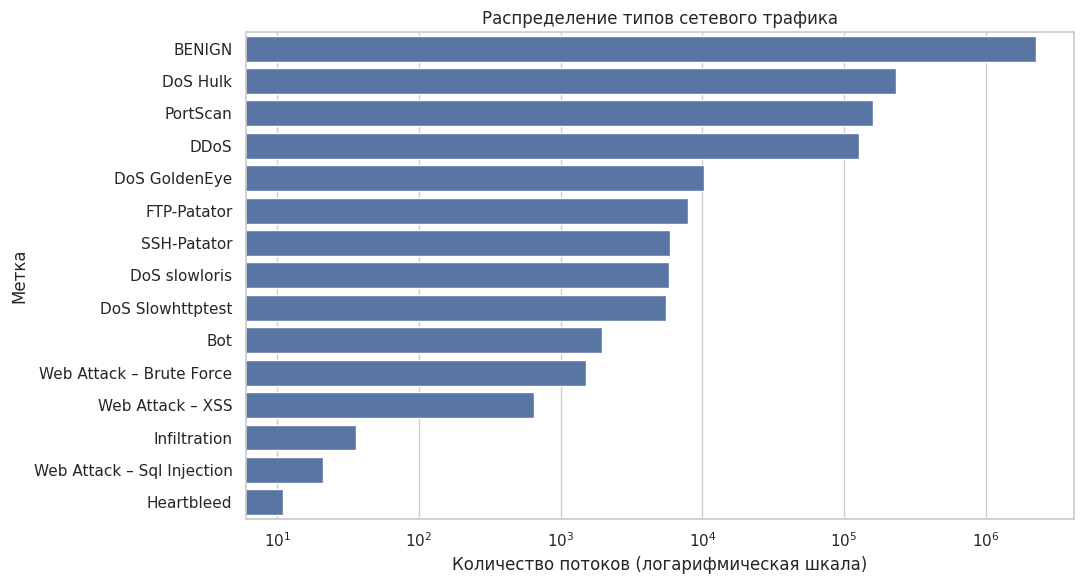

In [ ]:
label_counts = df["label"].value_counts()

label_summary = pd.DataFrame({
    "Количество": label_counts,
    "Доля, %": (label_counts / len(df) * 100).round(2)
})

display(label_summary)

plt.figure(figsize=(11, 6))
sns.barplot(
    x=label_counts.values,
    y=label_counts.index
)
plt.xscale("log")
plt.xlabel("Количество потоков (логарифмическая шкала)")
plt.ylabel("Метка")
plt.title("Распределение типов сетевого трафика")
plt.tight_layout()
plt.show()

Вывод по распределению типов трафика:
1. Класс BENIGN (нормальный трафик) составляет 80,3% всех наблюдений, тогда как на различные типы атак приходится около 19,7%.
2. Чаще всего встречаются DoS Hulk (8,16%), PortScan (5,61%) и DDoS (4,52%). Вместе они составляют значительную часть всей выборки.
3. Количество наблюдений существенно различается между типами атак. Например, DoS Hulk представлен более чем 231 тыс. записей, а Heartbleed всего 11. Это может затруднить выявление редких типов атак.

Для первоначального исследования целесообразно использовать бинарную классификацию: нормальный трафик против подозрительного. При этом необходимо учитывать дисбаланс классов и не допускать, чтобы качество модели определялось преимущественно наиболее многочисленным классом.

**Распределение длительности потоков.**

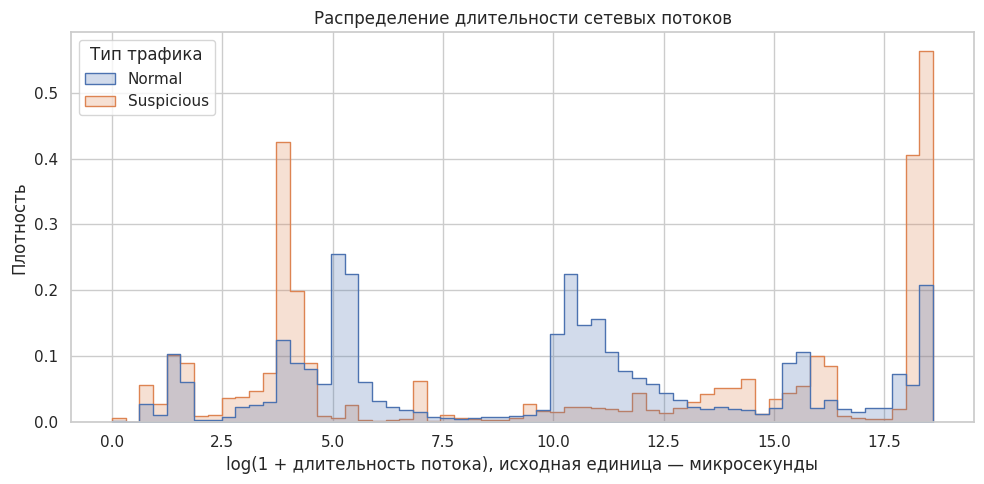

In [ ]:
if "flow_duration" in df.columns:
    plot_df = df.loc[
        df["flow_duration"].notna()
        & (df["flow_duration"] >= 0),
        ["flow_duration", "is_suspicious"]
    ].copy()

    plot_df["Тип трафика"] = plot_df["is_suspicious"].map({
        0: "Normal",
        1: "Suspicious"
    })

    plot_df["log_duration"] = np.log1p(plot_df["flow_duration"])

    plt.figure(figsize=(10, 5))
    sns.histplot(
        data=plot_df,
        x="log_duration",
        hue="Тип трафика",
        bins=60,
        stat="density",
        common_norm=False,
        element="step"
    )
    plt.xlabel("log(1 + длительность потока), исходная единица — микросекунды")
    plt.ylabel("Плотность")
    plt.title("Распределение длительности сетевых потоков")
    plt.tight_layout()
    plt.show()

По распределению длительности сетевых потоков:
1. Распределения нормального и подозрительного трафика различаются. У подозрительных потоков заметны пики около значений 4 и 18 по оси.

2. У нормального трафика выражены пики примерно в диапазонах 5–6 и 10–12, что указывает на другой характер длительности соединений.

3. Распределения частично перекрываются, поэтому одной длительности потока недостаточно для надёжного выявления атак.

**Сводная статистика по IP-адресам.**

In [ ]:
if "source_ip" in df.columns:
    ip_stats = (
        df.dropna(subset=["source_ip"])
        .groupby("source_ip")
        .agg(
            total_flows=("label", "size"),
            suspicious_flows=("is_suspicious", "sum"),
            suspicious_share=("is_suspicious", "mean")
        )
    )

    ip_stats["suspicious_share"] *= 100

    print("15 адресов с наибольшим количеством потоков:")
    display(
        ip_stats.sort_values(
            "total_flows", ascending=False
        ).head(15).round(2)
    )

    print("15 адресов с наибольшим количеством потоков, "
          "помеченных как атаки:")
    display(
        ip_stats.sort_values(
            "suspicious_flows", ascending=False
        ).head(15).round(2)
    )

15 адресов с наибольшим количеством потоков:


,total_flows,suspicious_flows,suspicious_share
source_ip,,,
172.16.0.1,559247,555641,99.36
192.168.10.3,298990,0,0.00
192.168.10.8,215280,307,0.14
192.168.10.5,170110,180,0.11
192.168.10.9,152536,226,0.15
192.168.10.12,146252,2,0.00
192.168.10.15,146036,371,0.25
192.168.10.14,140992,209,0.15
192.168.10.17,123187,2,0.00


15 адресов с наибольшим количеством потоков, помеченных как атаки:


,total_flows,suspicious_flows,suspicious_share
source_ip,,,
172.16.0.1,559247,555641,99.36
205.174.165.73,712,705,99.02
192.168.10.15,146036,371,0.25
192.168.10.8,215280,307,0.14
192.168.10.9,152536,226,0.15
192.168.10.14,140992,209,0.15
192.168.10.5,170110,180,0.11
192.168.10.50,82107,3,0.00
192.168.10.17,123187,2,0.00


Выводы по активности IP-адресов:
1. IP 172.16.0.1 выделяется сильнее всего: из 559 247 потоков 555 641 помечен как подозрительный (99,36%). Это может указывать на активность атак в датасете, но адрес может и обозначать узел лабораторной сети, а не реального внешнего злоумышленника.
2. Большинство других адресов 192.168.10.x имеют много потоков, но низкую долю подозрительных - обычно менее 0,3%. Большое количество соединений само по себе не означает атаку.
3. 205.174.165.73 также имеет высокую долю подозрительных потоков - 99,02%, хотя всего потоков 712.

**Корреляционная матрица.**

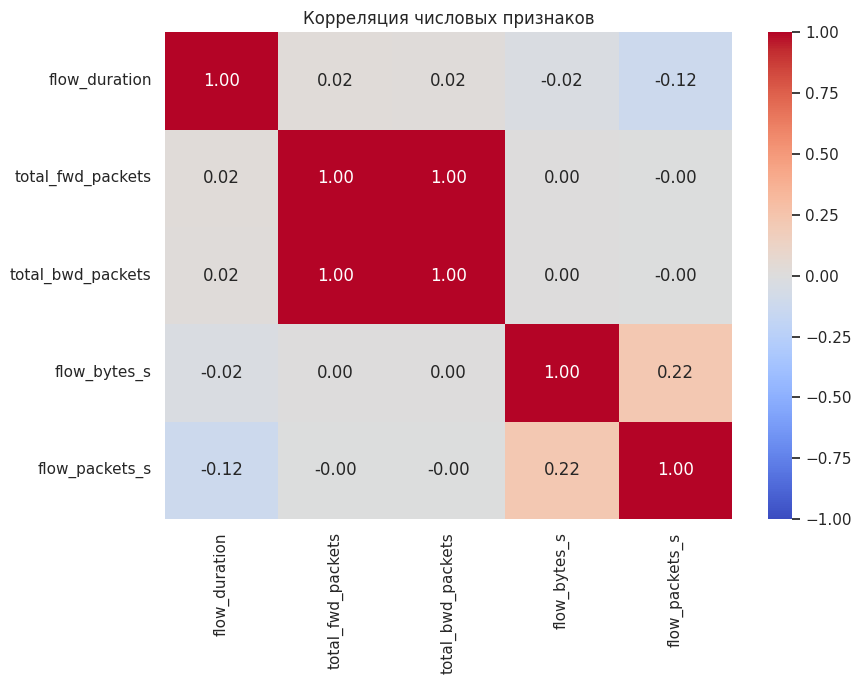

In [ ]:
corr_columns = [
    "flow_duration",
    "total_fwd_packets",
    "total_bwd_packets",
    "flow_bytes_s",
    "flow_packets_s"
]

corr_columns = [
    col for col in corr_columns
    if col in df.columns
]

corr_df = df[corr_columns].replace(
    [np.inf, -np.inf], np.nan
)

# Для ускорения расчёта используем случайную выборку
corr_df = corr_df.sample(
    n=min(100_000, len(corr_df)),
    random_state=42
).dropna()

corr = corr_df.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Корреляция числовых признаков")
plt.tight_layout()
plt.show()

По корреляции признаков:
1. total_fwd_packets и total_bwd_packets имеют почти идеальную корреляцию (1,00). В этом датасете количество входящих и исходящих пакетов тесно связано. Возможно, эти признаки частично дублируют информацию друг друга.

2. flow_bytes_s и flow_packets_s имеют слабую положительную корреляцию (0,22). Увеличение скорости передачи байтов может в некоторой степени быть связано с увеличением скорости передачи пакетов.

3. flow_duration слабо отрицательно коррелирует с flow_packets_s (-0,12). Линейная связь между длительностью потока и скоростью передачи пакетов небольшая.